# 07 | Customer Scoring and Segmentation

## Objective

Develop a reusable customer-level scoring and segmentation workflow using the selected 60-day repeat-purchase development model.

The workflow will generate predictions, group customers by relative repeat-purchase propensity and prepare structured outputs for downstream reporting and analysis.

## Development Scope

1. Load the existing customer feature dataset and saved development model.
2. Define the appropriate scoring population and validate eligibility.
3. Generate customer-level repeat-purchase propensity scores.
4. Create low-, medium- and high-propensity segments.
5. Analyse segment distributions and customer characteristics.
6. Validate scoring outputs and data quality.
7. Export reusable customer-level datasets for SQL and Power BI integration.

## Model

**Algorithm:** Imputation-aware Logistic Regression

**Regularisation:** C = 0.10

**Target:** Repeat purchase within 60 days of first purchase

**Model artifact:** `models/repeat_purchase_logistic_imputed_c010.joblib`

## Methodological Considerations

- Model scores describe predicted repeat-purchase propensity, not causal effects of marketing interventions.
- The development model has not undergone an independent post-selection holdout evaluation.
- Probability overestimation remains unresolved.
- Customer segments will initially use relative model-score rankings rather than fixed probability thresholds.
- Historical customers will be used to demonstrate the scoring workflow, not represented as current active customers.
- Customer identifiers and sensitive information should not be unnecessarily exposed in reporting outputs.

## Expected Deliverables

A validated customer-scoring dataset, interpretable propensity segments and reusable outputs for the wider Customer Intelligence Platform.

In [1]:
# Load customer features and the saved scoring model

from pathlib import Path
import pandas as pd
import numpy as np
import joblib

# Locate the project directory
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define existing project artifact paths
feature_path = (
    project_root / "data" / "processed" / "customer_features.pkl"
)

model_path = (
    project_root / "models" /
    "repeat_purchase_logistic_imputed_c010.joblib"
)

# Verify that both artifacts exist before loading
assert feature_path.is_file(), f"Feature dataset not found: {feature_path}"
assert model_path.is_file(), f"Model not found: {model_path}"

# Load existing artifacts
customer_features = pd.read_pickle(feature_path)
scoring_model = joblib.load(model_path)

# Retrieve the exact model feature requirements
model_features = list(scoring_model.feature_names_in_)

# Validate source data and model compatibility
missing_columns = sorted(
    set(model_features) - set(customer_features.columns)
)

print("Customer Scoring: Artifact Validation")
print("-" * 50)

print("Customer dataset shape:", customer_features.shape)
print("Model type:", type(scoring_model.named_steps["classifier"]).__name__)
print("Model feature count:", len(model_features))
print("Missing required columns:", missing_columns)

print(
    "Unique customers:",
    customer_features["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    customer_features["customer_unique_id"].duplicated().sum()
)

print(
    "Missing target values:",
    customer_features["repeat_purchase_60d"].isna().sum()
)

Customer Scoring: Artifact Validation
--------------------------------------------------
Customer dataset shape: (78100, 29)
Model type: LogisticRegression
Model feature count: 9
Missing required columns: []
Unique customers: 78100
Duplicate customers: 0
Missing target values: 0


In [2]:
# Prepare the historical customer scoring population

# Identify the required customer information
customer_columns = [
    "customer_unique_id",
    "order_id",
    "order_purchase_timestamp",
    "repeat_purchase_60d"
]

# Preserve identifiers and historical outcomes
scoring_customers = customer_features[
    customer_columns
].copy()

# Prepare the nine predictors expected by the saved model
X_scoring = customer_features[
    model_features
].copy()

# Validate scoring population
print("Customer Scoring Population")
print("-" * 50)

print("Customers prepared:", len(scoring_customers))

print(
    "Unique customers:",
    scoring_customers["customer_unique_id"].nunique()
)

print(
    "Duplicate customers:",
    scoring_customers["customer_unique_id"].duplicated().sum()
)

print(
    "Missing predictor values:",
    int(X_scoring.isna().sum().sum())
)

print(
    "Customers with at least one missing predictor:",
    int(X_scoring.isna().any(axis=1).sum())
)

print(
    "Prediction period:",
    scoring_customers["order_purchase_timestamp"].min(),
    "to",
    scoring_customers["order_purchase_timestamp"].max()
)

Customer Scoring Population
--------------------------------------------------
Customers prepared: 78100
Unique customers: 78100
Duplicate customers: 0
Missing predictor values: 4471
Customers with at least one missing predictor: 1903
Prediction period: 2016-09-04 21:15:19 to 2018-06-02 23:42:33


In [3]:
# Generate repeat-purchase propensity scores

# Predict the probability of a repeat purchase within 60 days
repeat_purchase_scores = scoring_model.predict_proba(
    X_scoring
)[:, 1]

# Attach predictions to the customer-level dataset
scoring_customers["repeat_purchase_propensity"] = (
    repeat_purchase_scores
)

# Validate generated predictions
assert len(scoring_customers) == len(customer_features)

assert scoring_customers[
    "repeat_purchase_propensity"
].notna().all(), "Missing propensity scores detected"

assert scoring_customers[
    "repeat_purchase_propensity"
].between(0, 1).all(), "Scores outside probability range"

assert (
    scoring_customers["customer_unique_id"].is_unique
), "Duplicate customers detected"

print("Repeat-Purchase Propensity Scoring")
print("-" * 50)

print("Customers scored:", len(scoring_customers))

print(
    "Minimum propensity:",
    round(scoring_customers["repeat_purchase_propensity"].min(), 4)
)

print(
    "Average propensity:",
    round(scoring_customers["repeat_purchase_propensity"].mean(), 4)
)

print(
    "Maximum propensity:",
    round(scoring_customers["repeat_purchase_propensity"].max(), 4)
)

print(
    "Missing scores:",
    scoring_customers["repeat_purchase_propensity"].isna().sum()
)

display(scoring_customers.head())

Repeat-Purchase Propensity Scoring
--------------------------------------------------
Customers scored: 78100
Minimum propensity: 0.0005
Average propensity: 0.0226
Maximum propensity: 0.4943
Missing scores: 0


,customer_unique_id,order_id,order_purchase_timestamp,repeat_purchase_60d,repeat_purchase_propensity
0,0000366f3b9a7992bf8c76cfdf3221e2,e22acc9c116caa3f2b7121bbb380d08e,2018-05-10 10:56:27,0,0.045277
1,0000b849f77a49e4a4ce2b2a4ca5be3f,3594e05a005ac4d06a72673270ef9ec9,2018-05-07 11:11:27,0,0.018012
2,0000f46a3911fa3c0805444483337064,b33ec3b699337181488304f362a6b734,2017-03-10 21:05:03,0,0.012786
3,0000f6ccb0745a6a4b88665a16c9f078,41272756ecddd9a9ed0180413cc22fb6,2017-10-12 20:29:41,0,0.017735
4,0004aac84e0df4da2b147fca70cf8255,d957021f1127559cd947b62533f484f7,2017-11-14 19:45:42,0,0.014317


Repeat-Purchase Propensity Distribution
--------------------------------------------------


,Propensity Score
count,78100.000000
mean,0.022629
std,0.012022
min,0.000545
10%,0.013330
25%,0.015602
50%,0.018877
75%,0.025756
90%,0.038240
95%,0.046174


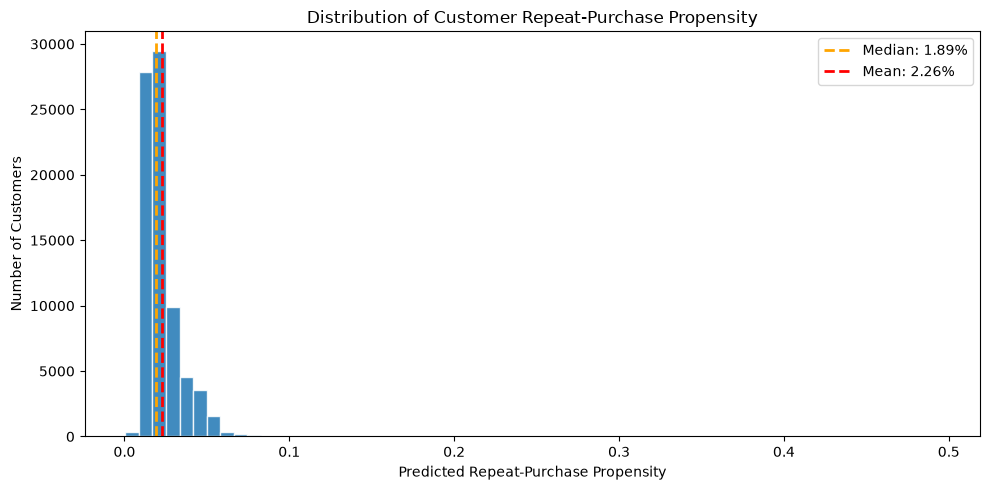

In [4]:
# Analyse the distribution of repeat-purchase propensity scores

import matplotlib.pyplot as plt

scores = scoring_customers["repeat_purchase_propensity"]

print("Repeat-Purchase Propensity Distribution")
print("-" * 50)

display(
    scores.describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame(name="Propensity Score")
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    scores,
    bins=60,
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    scores.median(),
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"Median: {scores.median():.2%}"
)

ax.axvline(
    scores.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {scores.mean():.2%}"
)

ax.set_title("Distribution of Customer Repeat-Purchase Propensity")
ax.set_xlabel("Predicted Repeat-Purchase Propensity")
ax.set_ylabel("Number of Customers")
ax.legend()

plt.tight_layout()
plt.show()

In [5]:
# Create customer segments using relative propensity rankings

segment_labels = [
    "Low Propensity",
    "Medium Propensity",
    "High Propensity"
]

# Rank scores to assign customers into non-overlapping groups
scoring_customers["propensity_segment"] = pd.qcut(
    scoring_customers["repeat_purchase_propensity"].rank(
        method="first"
    ),
    q=[0, 0.50, 0.80, 1.00],
    labels=segment_labels
)

# Summarise propensity segments
segment_summary = (
    scoring_customers
    .groupby("propensity_segment", observed=True)
    .agg(
        customers=("customer_unique_id", "nunique"),
        average_propensity=("repeat_purchase_propensity", "mean"),
        minimum_propensity=("repeat_purchase_propensity", "min"),
        maximum_propensity=("repeat_purchase_propensity", "max"),
        actual_repeat_rate=("repeat_purchase_60d", "mean"),
        repeat_customers=("repeat_purchase_60d", "sum")
    )
    .reset_index()
)

segment_summary["customer_share"] = (
    segment_summary["customers"] / len(scoring_customers)
)

# Format the summary for reporting
display_summary = segment_summary.copy()

for column in [
    "average_propensity",
    "minimum_propensity",
    "maximum_propensity",
    "actual_repeat_rate",
    "customer_share"
]:
    display_summary[column] = display_summary[column].map(
        lambda value: f"{value:.2%}"
    )

print("Customer Propensity Segmentation")
print("-" * 50)

display(display_summary)

print(
    "Total customers assigned:",
    segment_summary["customers"].sum()
)

print(
    "Customers without segments:",
    scoring_customers["propensity_segment"].isna().sum()
)

Customer Propensity Segmentation
--------------------------------------------------


,propensity_segment,customers,average_propensity,minimum_propensity,maximum_propensity,actual_repeat_rate,repeat_customers,customer_share
0,Low Propensity,39050,1.53%,0.05%,1.89%,1.37%,536,50.00%
1,Medium Propensity,23430,2.25%,1.89%,2.85%,2.11%,494,30.00%
2,High Propensity,15620,4.11%,2.85%,49.43%,3.58%,559,20.00%


Total customers assigned: 78100
Customers without segments: 0


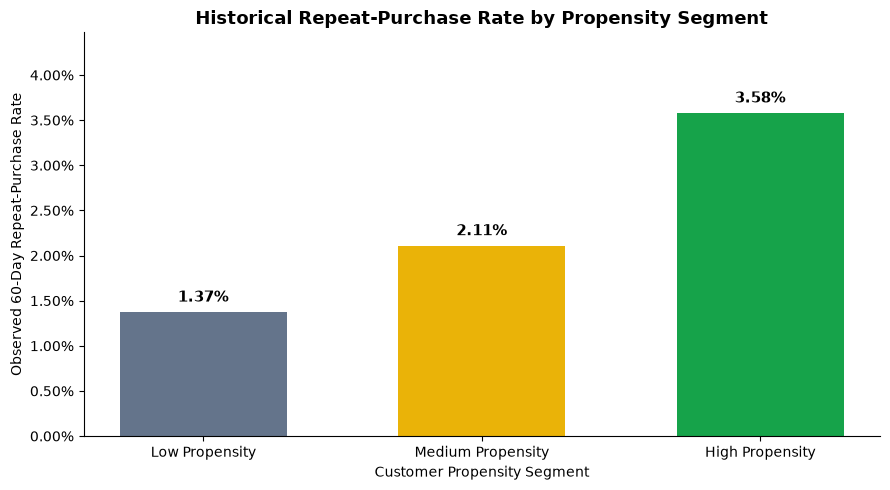

In [6]:
# Visualise observed repeat-purchase rates by propensity segment

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

segment_plot = segment_summary.copy()

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    segment_plot["propensity_segment"].astype(str),
    segment_plot["actual_repeat_rate"],
    color=["#64748B", "#EAB308", "#16A34A"],
    width=0.6
)

for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2%}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Historical Repeat-Purchase Rate by Propensity Segment",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Customer Propensity Segment")
ax.set_ylabel("Observed 60-Day Repeat-Purchase Rate")
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set_ylim(
    0,
    segment_plot["actual_repeat_rate"].max() * 1.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [7]:
# Compare customer purchasing characteristics across propensity segments

segment_profiles = scoring_customers[
    ["customer_unique_id", "propensity_segment"]
].merge(
    customer_features[
        [
            "customer_unique_id",
            "first_order_item_count",
            "first_order_product_count",
            "first_order_item_value",
            "first_order_freight_value"
        ]
    ],
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

segment_characteristics = (
    segment_profiles
    .groupby("propensity_segment", observed=True)
    .agg(
        customers=("customer_unique_id", "nunique"),
        avg_items=("first_order_item_count", "mean"),
        avg_products=("first_order_product_count", "mean"),
        avg_order_value=("first_order_item_value", "mean"),
        avg_freight_value=("first_order_freight_value", "mean")
    )
    .reset_index()
)

assert segment_characteristics["customers"].sum() == len(scoring_customers)

print("Customer Characteristics by Propensity Segment")
print("-" * 55)

display(
    segment_characteristics.round(2)
)

Customer Characteristics by Propensity Segment
-------------------------------------------------------


,propensity_segment,customers,avg_items,avg_products,avg_order_value,avg_freight_value
0,Low Propensity,39050,1.05,1.00,165.75,22.18
1,Medium Propensity,23430,1.15,1.03,110.53,21.71
2,High Propensity,15620,1.37,1.14,109.81,23.77


In [8]:
# Investigate first-order value distributions across propensity segments

order_value_profiles = segment_profiles.copy()

order_value_summary = (
    order_value_profiles
    .groupby("propensity_segment", observed=True)
    .agg(
        customers=("customer_unique_id", "nunique"),
        mean_order_value=("first_order_item_value", "mean"),
        median_order_value=("first_order_item_value", "median"),
        p75_order_value=(
            "first_order_item_value",
            lambda x: x.quantile(0.75)
        ),
        p95_order_value=(
            "first_order_item_value",
            lambda x: x.quantile(0.95)
        ),
        maximum_order_value=("first_order_item_value", "max")
    )
    .reset_index()
)

print("First-Order Item Value Distribution by Propensity Segment")
print("-" * 65)

display(order_value_summary.round(2))

First-Order Item Value Distribution by Propensity Segment
-----------------------------------------------------------------


,propensity_segment,customers,mean_order_value,median_order_value,p75_order_value,p95_order_value,maximum_order_value
0,Low Propensity,39050,165.75,95.20,174.0,589.00,13440.00
1,Medium Propensity,23430,110.53,78.76,130.0,319.98,2919.40
2,High Propensity,15620,109.81,83.79,135.0,275.94,3099.75


In [9]:
# Analyse observed repeat-purchase behaviour by first-order value

value_analysis = customer_features[
    [
        "customer_unique_id",
        "first_order_item_value",
        "repeat_purchase_60d"
    ]
].dropna(subset=["first_order_item_value"]).copy()

# Create five equally sized spending groups
value_analysis["spending_group"] = pd.qcut(
    value_analysis["first_order_item_value"].rank(method="first"),
    q=5,
    labels=[
        "Lowest 20%",
        "Low-Medium 20%",
        "Middle 20%",
        "High-Medium 20%",
        "Highest 20%"
    ]
)

spending_summary = (
    value_analysis
    .groupby("spending_group", observed=True)
    .agg(
        customers=("customer_unique_id", "nunique"),
        median_first_order_value=("first_order_item_value", "median"),
        mean_first_order_value=("first_order_item_value", "mean"),
        repeat_customers=("repeat_purchase_60d", "sum"),
        actual_repeat_rate=("repeat_purchase_60d", "mean")
    )
    .reset_index()
)

print("Observed Repeat-Purchase Behaviour by First-Order Spending")
print("-" * 65)

display(
    spending_summary.round(4)
)

Observed Repeat-Purchase Behaviour by First-Order Spending
-----------------------------------------------------------------


,spending_group,customers,median_first_order_value,mean_first_order_value,repeat_customers,actual_repeat_rate
0,Lowest 20%,15492,25.00,25.1497,354,0.0229
1,Low-Medium 20%,15491,50.90,52.3524,318,0.0205
2,Middle 20%,15492,87.00,86.2487,359,0.0232
3,High-Medium 20%,15491,134.90,136.4916,250,0.0161
4,Highest 20%,15492,271.99,390.8836,287,0.0185


In [10]:
# Combine first-order spending and repeat-purchase propensity

value_propensity = scoring_customers.merge(
    customer_features[
        ["customer_unique_id", "first_order_item_value"]
    ],
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

# Classify first-order spending relative to the historical median
median_order_value = value_propensity[
    "first_order_item_value"
].median()

value_propensity["initial_value_segment"] = np.select(
    [
        value_propensity["first_order_item_value"].isna(),
        value_propensity["first_order_item_value"] >= median_order_value
    ],
    [
        "Unknown Value",
        "Higher Initial Value"
    ],
    default="Lower Initial Value"
)

# Combine the two customer dimensions
customer_matrix = (
    value_propensity
    .groupby(
        ["initial_value_segment", "propensity_segment"],
        observed=True
    )
    .agg(
        customers=("customer_unique_id", "nunique"),
        average_first_order_value=("first_order_item_value", "mean"),
        average_propensity=("repeat_purchase_propensity", "mean"),
        actual_repeat_rate=("repeat_purchase_60d", "mean")
    )
    .reset_index()
)

customer_matrix["customer_share"] = (
    customer_matrix["customers"] / len(value_propensity)
)

print("Customer Value and Propensity Matrix")
print("-" * 60)

print(f"Median first-order item value: R${median_order_value:.2f}")

display(customer_matrix.round(4))

print(
    "Total customers:",
    customer_matrix["customers"].sum()
)

print(
    "Customers with unknown first-order value:",
    value_propensity["first_order_item_value"].isna().sum()
)

Customer Value and Propensity Matrix
------------------------------------------------------------
Median first-order item value: R$87.00


,initial_value_segment,propensity_segment,customers,average_first_order_value,average_propensity,actual_repeat_rate,customer_share
0,Higher Initial Value,Low Propensity,20931,270.7099,0.0150,0.0119,0.2680
1,Higher Initial Value,Medium Propensity,10543,188.7633,0.0226,0.0198,0.1350
2,Higher Initial Value,High Propensity,7287,173.0406,0.0432,0.0355,0.0933
3,Lower Initial Value,Low Propensity,18117,44.4873,0.0157,0.0157,0.2320
4,Lower Initial Value,Medium Propensity,12766,45.9115,0.0225,0.0221,0.1635
5,Lower Initial Value,High Propensity,7814,50.8503,0.0395,0.0363,0.1001
6,Unknown Value,Low Propensity,2,NaN,0.0184,1.0000,0.0000
7,Unknown Value,Medium Propensity,121,NaN,0.0267,0.0248,0.0015
8,Unknown Value,High Propensity,519,NaN,0.0340,0.0308,0.0066


Total customers: 78100
Customers with unknown first-order value: 642


In [11]:
# Validate customer value and propensity segmentation

print("Customer Matrix Validation")
print("-" * 55)

# Confirm complete customer coverage
print("Total source customers:", len(customer_features))
print("Total matrix customers:", customer_matrix["customers"].sum())

print(
    "Unique customer IDs:",
    value_propensity["customer_unique_id"].nunique()
)

print(
    "Missing propensity segments:",
    value_propensity["propensity_segment"].isna().sum()
)

# Investigate customers with unavailable first-order values
unknown_value_customers = value_propensity[
    value_propensity["initial_value_segment"] == "Unknown Value"
].copy()

unknown_value_summary = (
    unknown_value_customers
    .groupby("propensity_segment", observed=True)
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_customers=("repeat_purchase_60d", "sum"),
        observed_repeat_rate=("repeat_purchase_60d", "mean"),
        average_propensity=("repeat_purchase_propensity", "mean")
    )
    .reset_index()
)

display(unknown_value_summary)

# Confirm that all customers are assigned exactly once
assert value_propensity["customer_unique_id"].is_unique
assert customer_matrix["customers"].sum() == len(customer_features)
assert value_propensity["propensity_segment"].notna().all()

print("\nCustomer matrix validation passed.")

Customer Matrix Validation
-------------------------------------------------------
Total source customers: 78100
Total matrix customers: 78100
Unique customer IDs: 78100
Missing propensity segments: 0


,propensity_segment,customers,repeat_customers,observed_repeat_rate,average_propensity
0,Low Propensity,2,2,1.000000,0.018374
1,Medium Propensity,121,3,0.024793,0.026653
2,High Propensity,519,16,0.030829,0.034008



Customer matrix validation passed.


In [12]:
# Create customer profiles from initial spending and repeat-purchase propensity

profile_names = {
    ("Higher Initial Value", "High Propensity"): "Higher Value | High Propensity",
    ("Higher Initial Value", "Medium Propensity"): "Higher Value | Medium Propensity",
    ("Higher Initial Value", "Low Propensity"): "Higher Value | Low Propensity",
    ("Lower Initial Value", "High Propensity"): "Lower Value | High Propensity",
    ("Lower Initial Value", "Medium Propensity"): "Lower Value | Medium Propensity",
    ("Lower Initial Value", "Low Propensity"): "Lower Value | Low Propensity"
}

value_propensity["customer_profile"] = [
    profile_names.get(
        (value_segment, str(propensity_segment)),
        "Unknown Initial Value"
    )
    for value_segment, propensity_segment in zip(
        value_propensity["initial_value_segment"],
        value_propensity["propensity_segment"]
    )
]

profile_summary = (
    value_propensity
    .groupby("customer_profile", observed=True)
    .agg(
        customers=("customer_unique_id", "nunique"),
        repeat_customers=("repeat_purchase_60d", "sum"),
        actual_repeat_rate=("repeat_purchase_60d", "mean"),
        average_propensity=("repeat_purchase_propensity", "mean"),
        average_initial_order_value=("first_order_item_value", "mean")
    )
    .reset_index()
    .sort_values("customers", ascending=False)
)

profile_summary["customer_share"] = (
    profile_summary["customers"] / len(value_propensity)
)

assert profile_summary["customers"].sum() == len(value_propensity)
assert value_propensity["customer_profile"].notna().all()

print("Customer Intelligence Profiles")
print("-" * 60)

display(profile_summary.round(4))

print("Total customers profiled:", profile_summary["customers"].sum())
print(
    "Customers with unknown initial value:",
    (value_propensity["customer_profile"] == "Unknown Initial Value").sum()
)

Customer Intelligence Profiles
------------------------------------------------------------


,customer_profile,customers,repeat_customers,actual_repeat_rate,average_propensity,average_initial_order_value,customer_share
1,Higher Value | Low Propensity,20931,249,0.0119,0.0150,270.7099,0.2680
4,Lower Value | Low Propensity,18117,285,0.0157,0.0157,44.4873,0.2320
5,Lower Value | Medium Propensity,12766,282,0.0221,0.0225,45.9115,0.1635
2,Higher Value | Medium Propensity,10543,209,0.0198,0.0226,188.7633,0.1350
3,Lower Value | High Propensity,7814,284,0.0363,0.0395,50.8503,0.1001
0,Higher Value | High Propensity,7287,259,0.0355,0.0432,173.0406,0.0933
6,Unknown Initial Value,642,21,0.0327,0.0326,NaN,0.0082


Total customers profiled: 78100
Customers with unknown initial value: 642


In [13]:
# Prepare reusable customer intelligence dataset

customer_intelligence = value_propensity[
    [
        "customer_unique_id",
        "order_id",
        "order_purchase_timestamp",
        "first_order_item_value",
        "repeat_purchase_propensity",
        "propensity_segment",
        "initial_value_segment",
        "customer_profile",
        "repeat_purchase_60d"
    ]
].copy()

# Standardise data types
customer_intelligence["order_purchase_timestamp"] = pd.to_datetime(
    customer_intelligence["order_purchase_timestamp"]
)

for column in [
    "propensity_segment",
    "initial_value_segment",
    "customer_profile"
]:
    customer_intelligence[column] = (
        customer_intelligence[column].astype("string")
    )

# Validate output integrity
assert len(customer_intelligence) == 78100
assert customer_intelligence["customer_unique_id"].is_unique

assert customer_intelligence[
    "repeat_purchase_propensity"
].between(0, 1).all()

assert customer_intelligence[
    "customer_profile"
].notna().all()

assert customer_intelligence[
    "propensity_segment"
].notna().all()

assert customer_intelligence[
    "repeat_purchase_60d"
].isin([0, 1]).all()

print("Customer Intelligence Dataset Validation")
print("-" * 55)

print("Dataset shape:", customer_intelligence.shape)

print(
    "Unique customers:",
    customer_intelligence["customer_unique_id"].nunique()
)

print(
    "Missing customer profiles:",
    customer_intelligence["customer_profile"].isna().sum()
)

print(
    "Missing propensity scores:",
    customer_intelligence["repeat_purchase_propensity"].isna().sum()
)

print(
    "Customers with unknown initial value:",
    (
        customer_intelligence["initial_value_segment"]
        == "Unknown Value"
    ).sum()
)

display(customer_intelligence.head())

Customer Intelligence Dataset Validation
-------------------------------------------------------
Dataset shape: (78100, 9)
Unique customers: 78100
Missing customer profiles: 0
Missing propensity scores: 0
Customers with unknown initial value: 642


,customer_unique_id,order_id,order_purchase_timestamp,first_order_item_value,repeat_purchase_propensity,propensity_segment,initial_value_segment,customer_profile,repeat_purchase_60d
0,0000366f3b9a7992bf8c76cfdf3221e2,e22acc9c116caa3f2b7121bbb380d08e,2018-05-10 10:56:27,129.90,0.045277,High Propensity,Higher Initial Value,Higher Value | High Propensity,0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,3594e05a005ac4d06a72673270ef9ec9,2018-05-07 11:11:27,18.90,0.018012,Low Propensity,Lower Initial Value,Lower Value | Low Propensity,0
2,0000f46a3911fa3c0805444483337064,b33ec3b699337181488304f362a6b734,2017-03-10 21:05:03,69.00,0.012786,Low Propensity,Lower Initial Value,Lower Value | Low Propensity,0
3,0000f6ccb0745a6a4b88665a16c9f078,41272756ecddd9a9ed0180413cc22fb6,2017-10-12 20:29:41,25.99,0.017735,Low Propensity,Lower Initial Value,Lower Value | Low Propensity,0
4,0004aac84e0df4da2b147fca70cf8255,d957021f1127559cd947b62533f484f7,2017-11-14 19:45:42,180.00,0.014317,Low Propensity,Higher Initial Value,Higher Value | Low Propensity,0


In [14]:
# Export historical customer intelligence outputs

from pathlib import Path

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

parquet_path = output_dir / "customer_intelligence_historical.parquet"
csv_path = output_dir / "customer_intelligence_historical.csv"

# Export validated customer-level dataset
customer_intelligence.to_parquet(
    parquet_path,
    index=False
)

customer_intelligence.to_csv(
    csv_path,
    index=False,
    encoding="utf-8"
)

# Reload both files to verify successful export
parquet_check = pd.read_parquet(parquet_path)
csv_check = pd.read_csv(csv_path)

assert parquet_check.shape == customer_intelligence.shape
assert csv_check.shape == customer_intelligence.shape

assert parquet_check["customer_unique_id"].is_unique
assert csv_check["customer_unique_id"].is_unique

assert parquet_check["repeat_purchase_propensity"].notna().all()
assert csv_check["repeat_purchase_propensity"].notna().all()

print("Customer Intelligence Export Validation")
print("-" * 55)

print("Parquet file:", parquet_path.name)
print("CSV file:", csv_path.name)
print("Records exported:", len(customer_intelligence))
print("Columns exported:", len(customer_intelligence.columns))
print("Parquet validation: Passed")
print("CSV validation: Passed")

Customer Intelligence Export Validation
-------------------------------------------------------
Parquet file: customer_intelligence_historical.parquet
CSV file: customer_intelligence_historical.csv
Records exported: 78100
Columns exported: 9
Parquet validation: Passed
CSV validation: Passed


## Conclusion and Business Insights

### Objective

Transform the existing repeat-purchase prediction model into a reusable customer-level scoring and segmentation workflow.

### Key Outcomes

- Successfully generated repeat-purchase propensity scores for 78,100 historical customers.
- Created low-, medium- and high-propensity segments.
- Developed customer profiles combining initial order spending with repeat-purchase propensity.
- Validated customer coverage, profile assignments and scoring outputs.
- Exported customer-level intelligence datasets in Parquet and CSV formats.

### Business Findings

**Repeat-purchase propensity differentiates historical purchasing behaviour.**

- Low-propensity customers recorded a 1.37% repeat-purchase rate.
- Medium-propensity customers recorded a 2.11% repeat-purchase rate.
- High-propensity customers recorded a 3.58% repeat-purchase rate.

The highest-ranked 20% of customers had approximately 2.6 times the observed repeat-purchase rate of the lowest-ranked 50%.

**Higher initial spending does not necessarily indicate stronger repeat-purchase behaviour.**

Customers with higher initial order values did not consistently demonstrate higher 60-day repeat-purchase rates.

**Combining spending and propensity creates more informative customer profiles.**

The largest profile, Higher Value | Low Propensity, contained 20,931 customers and recorded a 1.19% historical repeat-purchase rate.

These profiles provide opportunities for further customer research and controlled marketing experiments.

### Data Quality and Limitations

- All 78,100 historical customers received valid propensity scores.
- 642 customers had missing first-order item values and were assigned to an Unknown Initial Value profile.
- The scoring population includes customers used during model development.
- Historical segment results are descriptive and do not constitute independent model validation.
- Model probabilities remain imperfectly calibrated.
- Initial order value is not equivalent to customer lifetime value or profitability.
- Customer profiles should not be used for automated marketing decisions without further validation.

### Deliverables

- `data/processed/customer_intelligence_historical.parquet`
- `data/processed/customer_intelligence_historical.csv`

### Next Development Priorities

Connect customer intelligence outputs to PostgreSQL and Power BI, develop business-facing KPIs, and assess the usefulness of the scoring system for customer decision-making.